# ✈️ Flight Fare Prediction — End-to-End Analysis & Modelling

**Goal:** understand what drives domestic-India flight fares and build a model that predicts the fare of a flight.

**Notebook roadmap**
1. Setup & data loading
2. Data audit & cleaning
3. Feature engineering
4. Exploratory data analysis (EDA) with business insights
5. Modelling (baseline → linear → trees → boosting)
6. Hyper-parameter tuning
7. Final evaluation, error analysis & feature importance
8. Saving the model & making predictions
9. Conclusions and next steps

> **How to run:** keep `Cleaned_dataset.csv` in the same folder as this notebook (in Google Colab, the notebook will ask you to upload it) and use **Kernel → Restart & Run All**. Every cell is independent of manual edits and runs top-to-bottom.

## 1. Setup & data loading

In [ ]:
# !pip install -q scikit-learn==1.8.0

In [2]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             median_absolute_error, mean_absolute_percentage_error)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) <= 1.5 else f"{v:,.1f}")
print("Libraries loaded.")

Libraries loaded.


In [3]:
import sklearn; print(sklearn.__version__)   # 1.8.0

1.8.0


In [4]:
df_raw = pd.read_csv("Cleaned_dataset.csv")
df_raw.head()

,Date_of_journey,Journey_day,Airline,Flight_code,Class,Source,Departure,Total_stops,Arrival,Destination,Duration_in_hours,Days_left,Fare
0,2023-01-16,Monday,SpiceJet,SG-8169,Economy,Delhi,After 6 PM,non-stop,After 6 PM,Mumbai,2.1,1,5335
1,2023-01-16,Monday,Indigo,6E-2519,Economy,Delhi,After 6 PM,non-stop,Before 6 AM,Mumbai,2.3,1,5899
2,2023-01-16,Monday,GO FIRST,G8-354,Economy,Delhi,After 6 PM,non-stop,Before 6 AM,Mumbai,2.2,1,5801
3,2023-01-16,Monday,SpiceJet,SG-8709,Economy,Delhi,After 6 PM,non-stop,After 6 PM,Mumbai,2.1,1,5794
4,2023-01-16,Monday,Air India,AI-805,Economy,Delhi,After 6 PM,non-stop,After 6 PM,Mumbai,2.2,1,5955


## 2. Data audit & cleaning
Before analysing anything we check: data types, missing values, duplicates, impossible values and consistency between columns.

In [5]:
df = df_raw.copy()
df.columns = df.columns.str.strip()

expected = {"Date_of_journey", "Journey_day", "Airline", "Flight_code", "Class", "Source", "Departure",
            "Total_stops", "Arrival", "Destination", "Duration_in_hours", "Days_left", "Fare"}
missing_cols = expected - set(df.columns)
assert not missing_cols, f"Missing expected columns: {missing_cols}"

# remove stray whitespace in text columns
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].astype(str).str.strip()

print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values per column:")
display(df.isna().sum().to_frame("missing"))
print("Unique values per column:")
display(df.nunique().to_frame("n_unique"))

Data types:


,dtype
Date_of_journey,object
Journey_day,object
Airline,object
Flight_code,object
Class,object
Source,object
Departure,object
Total_stops,object
Arrival,object
Destination,object


Missing values per column:


,missing
Date_of_journey,0
Journey_day,0
Airline,0
Flight_code,0
Class,0
Source,0
Departure,0
Total_stops,0
Arrival,0
Destination,0


Unique values per column:


,n_unique
Date_of_journey,50
Journey_day,7
Airline,9
Flight_code,1405
Class,4
Source,7
Departure,4
Total_stops,3
Arrival,4
Destination,7


In [6]:
# --- quality checks -------------------------------------------------------
n_before = len(df)
n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed       : {n_dupes}  ({n_before:,} -> {len(df):,} rows)")

print(f"Fare <= 0                    : {(df['Fare'] <= 0).sum()}")
print(f"Duration <= 0                : {(df['Duration_in_hours'] <= 0).sum()}")
print(f"Days_left < 0                : {(df['Days_left'] < 0).sum()}")
print(f"Source == Destination        : {(df['Source'] == df['Destination']).sum()}")

df["Date_of_journey"] = pd.to_datetime(df["Date_of_journey"])
consistent = (df["Date_of_journey"].dt.day_name() == df["Journey_day"]).mean()
print(f"Journey_day matches the date : {consistent:.1%}")
print(f"Date range                   : {df['Date_of_journey'].min().date()} -> {df['Date_of_journey'].max().date()}")

Duplicate rows removed       : 6722  (452,088 -> 445,366 rows)
Fare <= 0                    : 0
Duration <= 0                : 0
Days_left < 0                : 0
Source == Destination        : 0
Journey_day matches the date : 100.0%
Date range                   : 2023-01-16 -> 2023-03-06


**Audit summary:** the data has no missing values and no impossible values, so only exact duplicate rows (about 1.5% of the data) were removed. Removing them *before* the train/test split also prevents identical rows from landing in both sets, which would inflate the test score. The `Journey_year` column in the original notebook was constant (all flights are in 2023), so it carries no information and is **not** used.

## 3. Feature engineering

In [7]:
# 3.1 Number of stops: text -> number  ('non-stop' -> 0, '1-stop' -> 1, '2+-stop' -> 2)
df["Stops"] = (df["Total_stops"].str.extract(r"(\d+)")[0].astype(float).fillna(0).astype(int))

# 3.2 Calendar features from the journey date
df["Day_index"] = (df["Date_of_journey"] - df["Date_of_journey"].min()).dt.days   # 0 = first date in data

# 3.3 Route (used for EDA)
df["Route"] = df["Source"] + " -> " + df["Destination"]

# 3.4 Booking window buckets (used for EDA)
df["Booking_window"] = pd.cut(df["Days_left"], bins=[0, 3, 7, 14, 21, 30, 50],
                              labels=["1-3", "4-7", "8-14", "15-21", "22-30", "31-50"])

# Orders used for nicer charts
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
TIME_ORDER = ["Before 6 AM", "6 AM - 12 PM", "12 PM - 6 PM", "After 6 PM"]
CLASS_ORDER = ["Economy", "Premium Economy", "Business", "First"]

# 'Flight_code' (1,400+ unique values) and the raw date are not used as model inputs:
# the airline is already captured by 'Airline', and the date is shown below to be redundant with 'Days_left'.
df[["Date_of_journey", "Total_stops", "Stops", "Day_index", "Route", "Booking_window"]].head()

,Date_of_journey,Total_stops,Stops,Day_index,Route,Booking_window
0,2023-01-16,non-stop,0,0,Delhi -> Mumbai,1-3
1,2023-01-16,non-stop,0,0,Delhi -> Mumbai,1-3
2,2023-01-16,non-stop,0,0,Delhi -> Mumbai,1-3
3,2023-01-16,non-stop,0,0,Delhi -> Mumbai,1-3
4,2023-01-16,non-stop,0,0,Delhi -> Mumbai,1-3


## 4. Exploratory data analysis
Fares are heavily driven by **travel class**, so we repeatedly look at *Economy* separately — that is where most passengers are, and comparing airlines or routes across classes would be misleading.

### 4.1 Target variable: Fare

,count,mean,median,min,max
Class,,,,,
Economy,248323,"10,164.1","9,494.0",1307,54600
Premium Economy,70364,"16,225.0","14,956.0",3439,73550
Business,126535,"51,632.3","50,409.0",12000,143019
First,144,"60,731.1","51,268.0",50855,102321


Overall skewness of Fare: 1.32


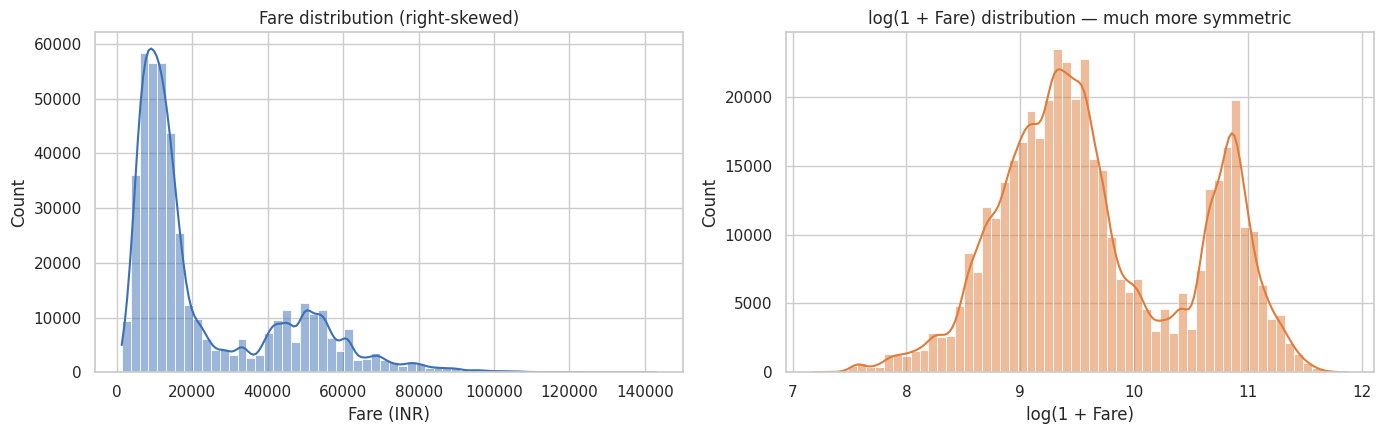

In [8]:
fare_summary = df.groupby("Class")["Fare"].agg(["count", "mean", "median", "min", "max"]).reindex(CLASS_ORDER)
display(fare_summary)
print(f"Overall skewness of Fare: {df['Fare'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["Fare"], bins=60, kde=True, ax=axes[0], color="#3b6fb6")
axes[0].set_title("Fare distribution (right-skewed)")
axes[0].set_xlabel("Fare (INR)")

sns.histplot(np.log1p(df["Fare"]), bins=60, kde=True, ax=axes[1], color="#e07b39")
axes[1].set_title("log(1 + Fare) distribution — much more symmetric")
axes[1].set_xlabel("log(1 + Fare)")
plt.tight_layout()
plt.show()

The fare is right-skewed and **multi-modal** (the cheap peak is Economy, the high peak is Business). A log transform makes the target far better behaved, so we will train models on `log(1 + Fare)` and convert predictions back to rupees.

### 4.2 What does the data contain? (category counts)

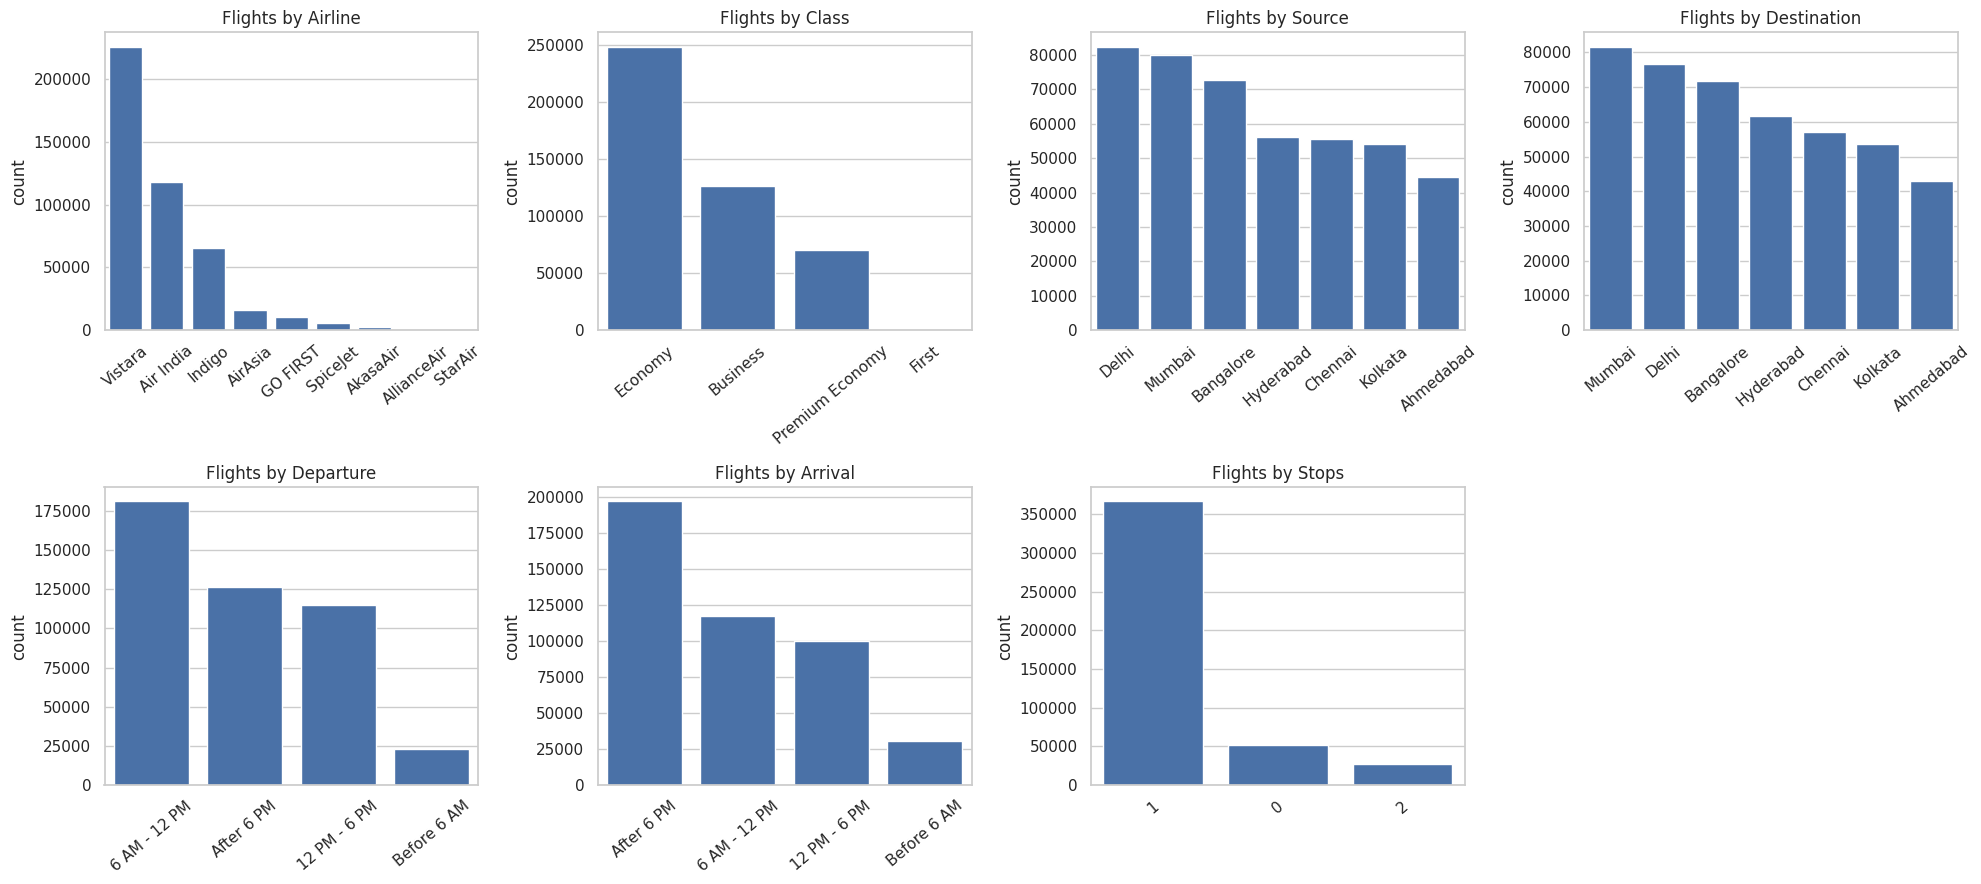

Share of flights by class:


,percent
Class,
Economy,55.8
Business,28.4
Premium Economy,15.8
First,0.0300


In [9]:
cat_cols_eda = ["Airline", "Class", "Source", "Destination", "Departure", "Arrival", "Stops"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()
for ax, col in zip(axes, cat_cols_eda):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color="#3b6fb6")
    ax.set_title(f"Flights by {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=40)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

print("Share of flights by class:")
display((df["Class"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

### 4.3 Travel class

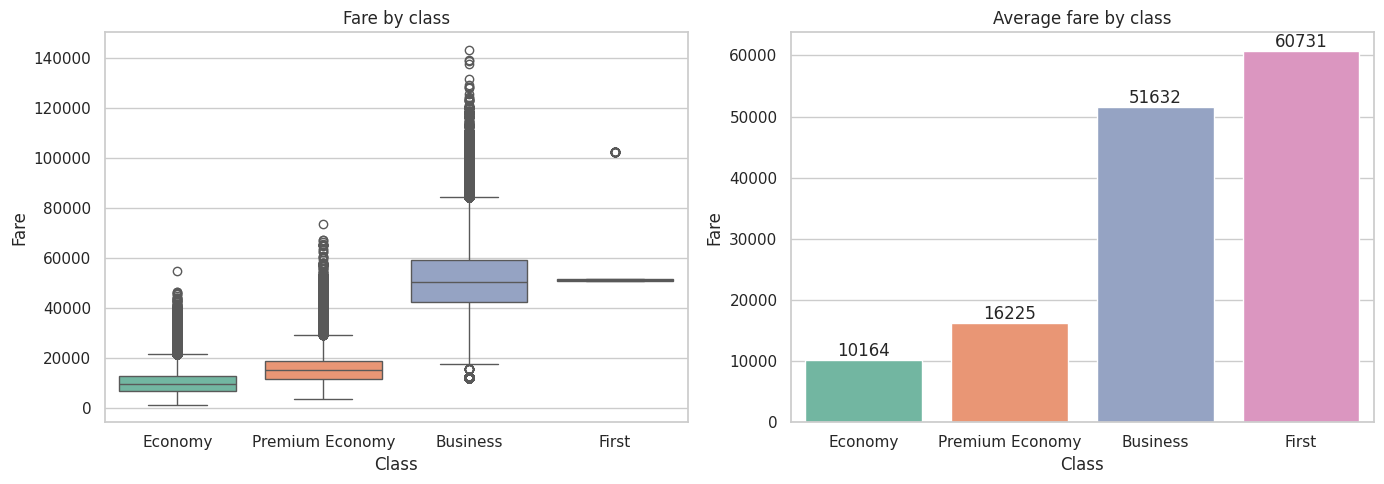

Premium Economy :  1.6x the average Economy fare
Business        :  5.1x the average Economy fare
First           :  6.0x the average Economy fare


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Class", y="Fare", order=CLASS_ORDER, ax=axes[0], palette="Set2", hue="Class", legend=False)
axes[0].set_title("Fare by class")
sns.barplot(data=df, x="Class", y="Fare", order=CLASS_ORDER, estimator="mean", errorbar=None,
            ax=axes[1], palette="Set2", hue="Class", legend=False)
axes[1].set_title("Average fare by class")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f")
plt.tight_layout()
plt.show()

eco = df.loc[df["Class"] == "Economy", "Fare"].mean()
for c in ["Premium Economy", "Business", "First"]:
    print(f"{c:16s}: {df.loc[df['Class'] == c, 'Fare'].mean() / eco:4.1f}x the average Economy fare")

### 4.4 Airlines (Economy only, for a fair comparison)

Which airline sells which class (number of flights):


Class,Economy,Premium Economy,Business,First
Airline,,,,
Air India,66005,0,52256,144
AirAsia,15764,0,0,0
AkasaAir,2230,0,0,0
AllianceAir,393,0,0,0
GO FIRST,10786,0,0,0
Indigo,65659,0,0,0
SpiceJet,5863,0,0,0
StarAir,62,0,0,0
Vistara,81561,70364,74279,0


,count,mean,median
Airline,,,
Vistara,81561,"12,081.9","11,572.0"
Air India,66005,"11,276.0","10,868.0"
StarAir,62,"9,792.8","4,688.0"
Indigo,65659,"8,198.8","7,557.0"
SpiceJet,5863,"8,109.8","7,555.0"
GO FIRST,10786,"8,015.1","7,110.0"
AirAsia,15764,"7,092.3","6,478.0"
AllianceAir,393,"4,077.5","3,799.0"
AkasaAir,2230,"3,570.0","2,893.0"


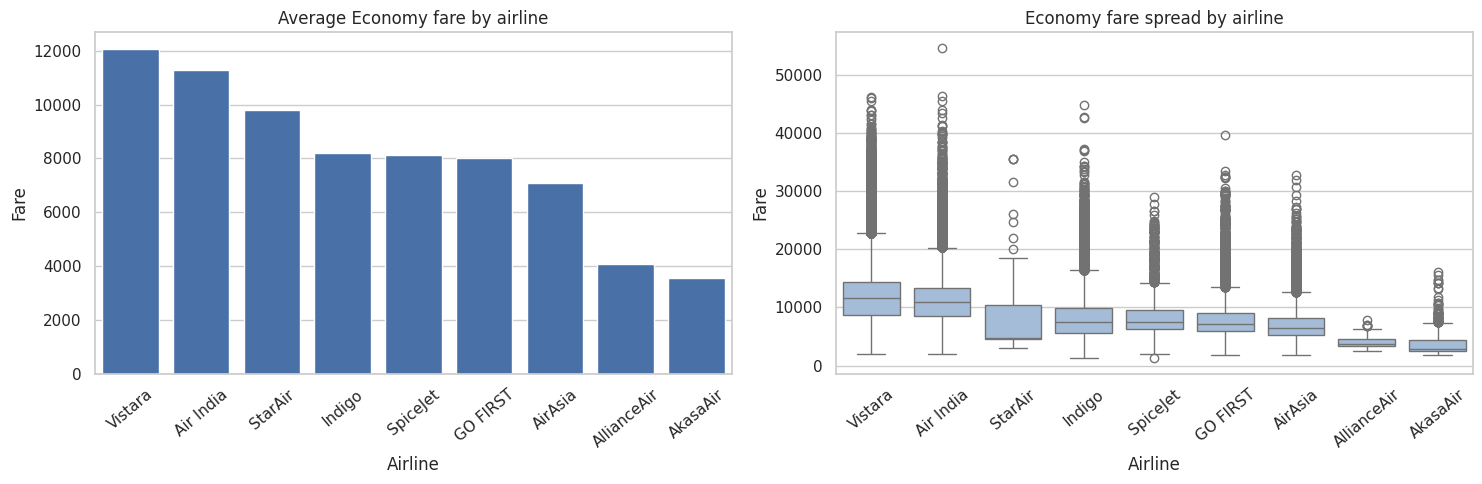

Average fare over ALL classes (misleading, because Business tickets exist only on Air India & Vistara):


,mean_fare_all_classes
Airline,
Vistara,"27,438.4"
Air India,"27,082.5"
StarAir,"9,792.8"
Indigo,"8,198.8"
SpiceJet,"8,109.8"
GO FIRST,"8,015.1"
AirAsia,"7,092.3"
AllianceAir,"4,077.5"
AkasaAir,"3,570.0"


In [11]:
print("Which airline sells which class (number of flights):")
display(pd.crosstab(df["Airline"], df["Class"])[CLASS_ORDER])

economy = df[df["Class"] == "Economy"]
airline_eco = economy.groupby("Airline")["Fare"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False)
display(airline_eco)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = airline_eco.index
sns.barplot(data=economy, x="Airline", y="Fare", order=order, errorbar=None, ax=axes[0], color="#3b6fb6")
axes[0].set_title("Average Economy fare by airline")
axes[0].tick_params(axis="x", rotation=40)
sns.boxplot(data=economy, x="Airline", y="Fare", order=order, ax=axes[1], color="#9bbbe0")
axes[1].set_title("Economy fare spread by airline")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

print("Average fare over ALL classes (misleading, because Business tickets exist only on Air India & Vistara):")
display(df.groupby("Airline")["Fare"].mean().sort_values(ascending=False).to_frame("mean_fare_all_classes"))

### 4.5 Number of stops

Class,Economy,Premium Economy,Business
Stops,,,
0,"5,723.4","8,760.4","27,523.3"
1,"10,731.2","16,410.5","53,543.6"
2,"13,116.5","19,689.1","66,058.8"


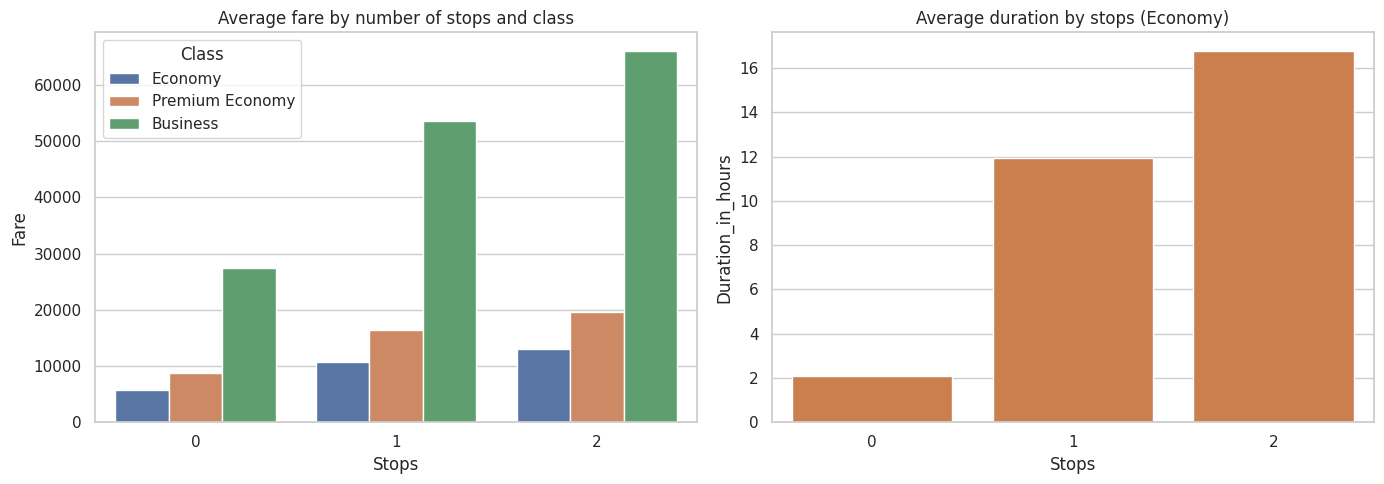

In [12]:
stops_class = df.groupby(["Class", "Stops"])["Fare"].agg(["count", "mean"]).reset_index()
display(stops_class.pivot(index="Stops", columns="Class", values="mean")[["Economy", "Premium Economy", "Business"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x="Stops", y="Fare", hue="Class", hue_order=CLASS_ORDER[:3], errorbar=None, ax=axes[0])
axes[0].set_title("Average fare by number of stops and class")
sns.barplot(data=economy, x="Stops", y="Duration_in_hours", errorbar=None, ax=axes[1], color="#e07b39")
axes[1].set_title("Average duration by stops (Economy)")
plt.tight_layout()
plt.show()

In **every class**, fares rise with the number of stops, and non-stop flights are the cheapest. This is partly a *confounding* effect: multi-stop itineraries are longer, and they are more common on the pricier full-service airlines. Stops explain about as much of the Economy fare variance as the airline does, so both stay in the model.

### 4.6 Flight duration

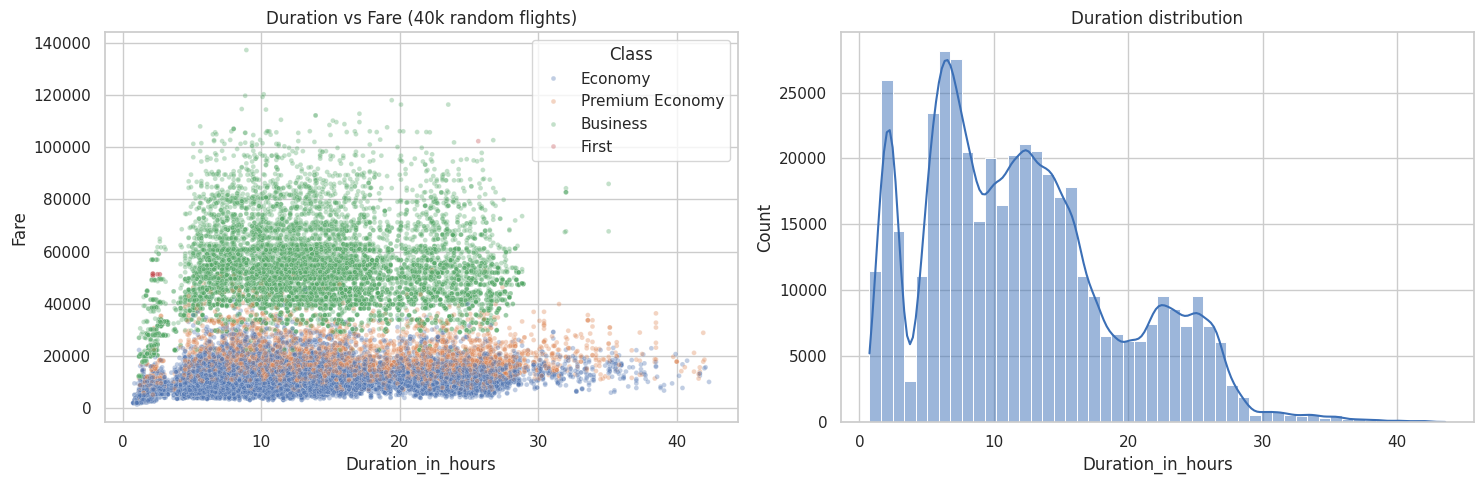

Correlation of Duration with Fare, per class (First excluded: only 144 rows):


,corr_with_fare
Class,
Business,0.1766
Economy,0.3328
Premium Economy,0.1643


In [13]:
sample_size = min(40000, len(df))

sample = df.sample(sample_size, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=sample, x="Duration_in_hours", y="Fare", hue="Class", hue_order=CLASS_ORDER,
                alpha=0.35, s=12, ax=axes[0])
axes[0].set_title("Duration vs Fare (40k random flights)")
sns.histplot(df["Duration_in_hours"], bins=50, kde=True, ax=axes[1], color="#3b6fb6")
axes[1].set_title("Duration distribution")
plt.tight_layout()
plt.show()

print("Correlation of Duration with Fare, per class (First excluded: only 144 rows):")
display(df[df["Class"] != "First"].groupby("Class")[["Duration_in_hours", "Fare"]].corr().iloc[0::2, 1].droplevel(1).to_frame("corr_with_fare"))

### 4.7 Booking window (days left before departure)

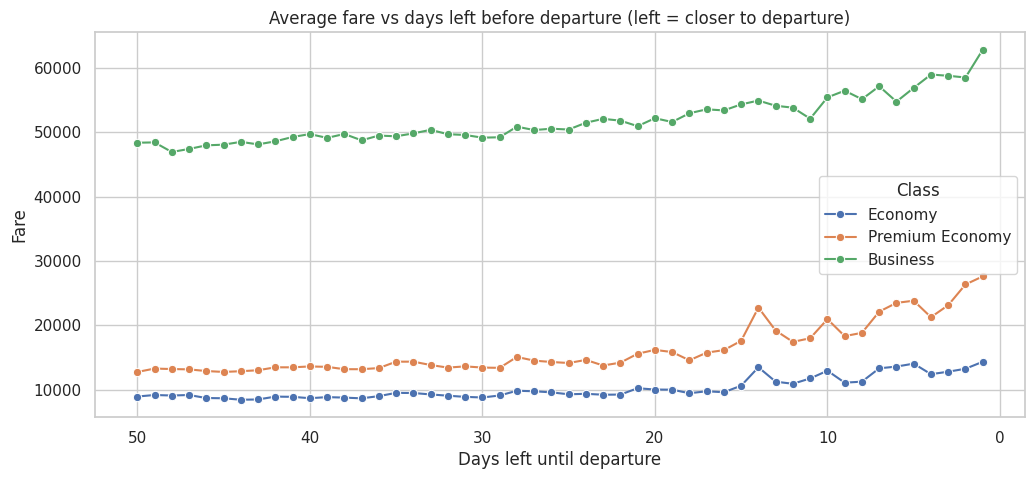

Class,Business,Economy
Booking_window,,
1-3,"60,060.1","13,461.2"
4-7,"56,872.3","13,326.2"
8-14,"54,532.0","11,811.4"
15-21,"52,697.8","9,945.0"
22-30,"50,630.9","9,340.1"
31-50,"48,837.4","8,923.1"


Economy: booking within 3 days costs 1.49x the fare of booking 22+ days ahead (13,461 vs 9,054 INR)


In [14]:
trend = df.groupby(["Days_left", "Class"])["Fare"].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=trend, x="Days_left", y="Fare", hue="Class", hue_order=CLASS_ORDER[:3], marker="o")
plt.gca().invert_xaxis()
plt.title("Average fare vs days left before departure (left = closer to departure)")
plt.xlabel("Days left until departure")
plt.show()

window = (df[df["Class"].isin(["Economy", "Business"])]
          .groupby(["Booking_window", "Class"], observed=True)["Fare"].mean().unstack())
display(window)

near = economy.loc[economy["Days_left"] <= 3, "Fare"].mean()
far = economy.loc[economy["Days_left"] >= 22, "Fare"].mean()
print(f"Economy: booking within 3 days costs {near / far:.2f}x the fare of booking 22+ days ahead "
      f"({near:,.0f} vs {far:,.0f} INR)")

### 4.8 Routes, departure time and day of week (Economy)

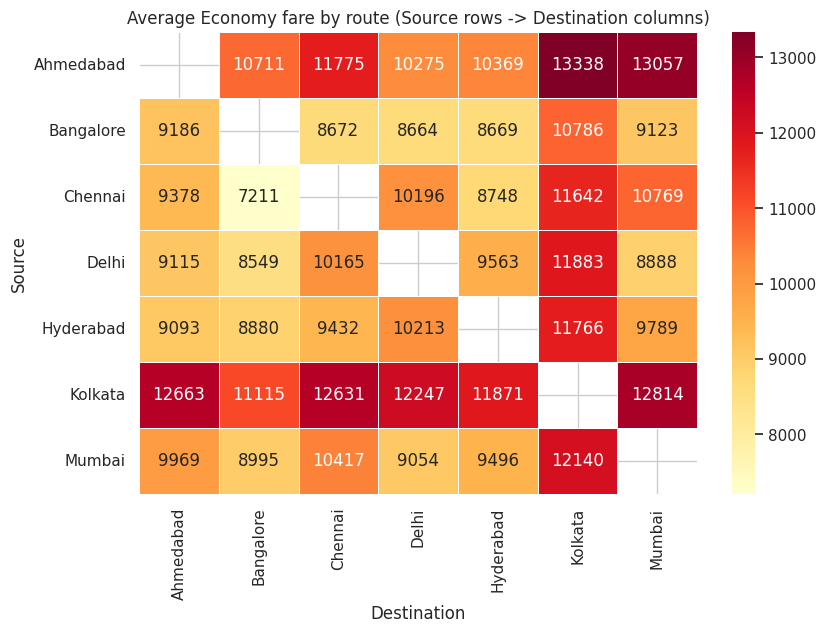

5 cheapest routes : Chennai -> Bangalore (7,211), Delhi -> Bangalore (8,549), Bangalore -> Delhi (8,664), Bangalore -> Hyderabad (8,669), Bangalore -> Chennai (8,672)
5 costliest routes: Kolkata -> Chennai (12,631), Kolkata -> Ahmedabad (12,663), Kolkata -> Mumbai (12,814), Ahmedabad -> Mumbai (13,057), Ahmedabad -> Kolkata (13,338)


In [15]:
pivot = economy.pivot_table(values="Fare", index="Source", columns="Destination", aggfunc="mean")
plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Average Economy fare by route (Source rows -> Destination columns)")
plt.show()

route_rank = economy.groupby("Route")["Fare"].mean().sort_values()
print("5 cheapest routes :", ", ".join(f"{r} ({v:,.0f})" for r, v in route_rank.head(5).items()))
print("5 costliest routes:", ", ".join(f"{r} ({v:,.0f})" for r, v in route_rank.tail(5).items()))

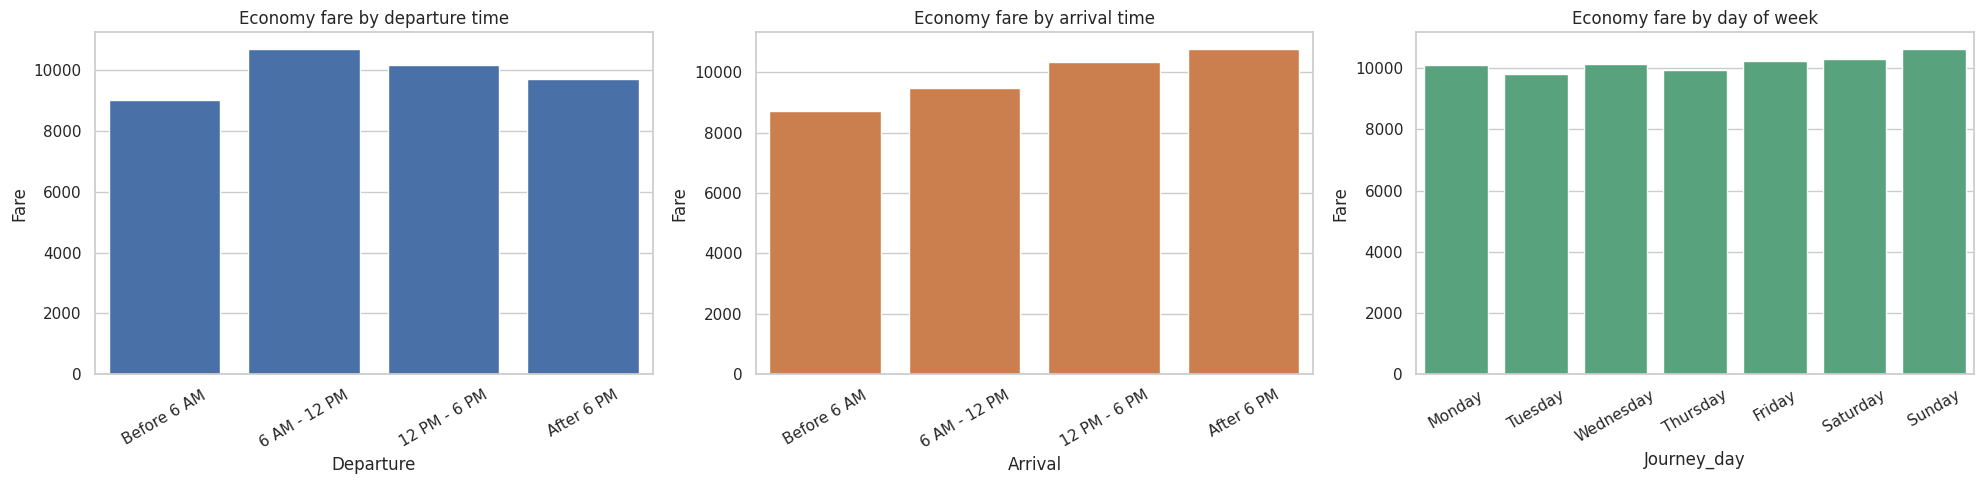

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.barplot(data=economy, x="Departure", y="Fare", order=TIME_ORDER, errorbar=None, ax=axes[0], color="#3b6fb6")
axes[0].set_title("Economy fare by departure time")
sns.barplot(data=economy, x="Arrival", y="Fare", order=TIME_ORDER, errorbar=None, ax=axes[1], color="#e07b39")
axes[1].set_title("Economy fare by arrival time")
sns.barplot(data=economy, x="Journey_day", y="Fare", order=DAY_ORDER, errorbar=None, ax=axes[2], color="#4caf7d")
axes[2].set_title("Economy fare by day of week")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### 4.9 Is the journey date a separate signal from `Days_left`?

In [17]:
# How many different Days_left values does each journey date have?
per_date = df.groupby("Date_of_journey")["Days_left"].nunique()
print("Distinct Days_left values per journey date:", per_date.unique())
print("Days_left == (days since first date + 1) for every row:", bool(((df["Day_index"] + 1) == df["Days_left"]).all()))
implied_scrape_date = (df["Date_of_journey"] - pd.to_timedelta(df["Days_left"], unit="D")).unique()
print("Implied date on which all prices were collected:", [str(pd.Timestamp(d).date()) for d in implied_scrape_date])

Distinct Days_left values per journey date: [1]
Days_left == (days since first date + 1) for every row: True
Implied date on which all prices were collected: ['2023-01-15']


**Important data insight:** every journey date has exactly one `Days_left` value, i.e. all prices were collected on a **single day**. Therefore the journey date and the booking window are the *same* signal (perfectly collinear): we cannot tell whether a fare is high because the flight is soon or because of the specific calendar date (holidays, events). Consequences:
* the date is **not** added as a separate model feature (it would add no information);
* the "booking early" finding above should be read as *"flights that depart sooner were priced higher on the collection day"*. Collecting prices on several dates would be needed to prove a true booking-time effect.

### 4.10 Correlations and how much each feature explains

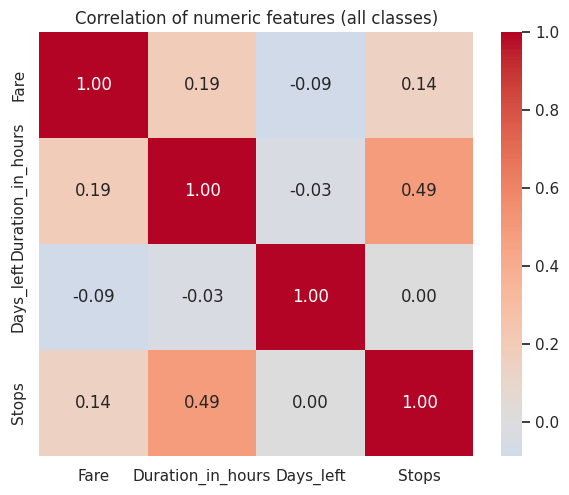

In [18]:
num_for_corr = df[["Fare", "Duration_in_hours", "Days_left", "Stops"]]
plt.figure(figsize=(7, 5.5))
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features (all classes)")
plt.show()

,All classes,Economy only
Class,0.7994,0.0000
Airline,0.1593,0.1870
Stops,0.0566,0.1798
Route,0.0150,0.0928
Arrival,0.0084,0.0230
Departure,0.0076,0.0124
Source,0.0056,0.0450
Destination,0.0046,0.0258
Journey_day,0.0002,0.0028


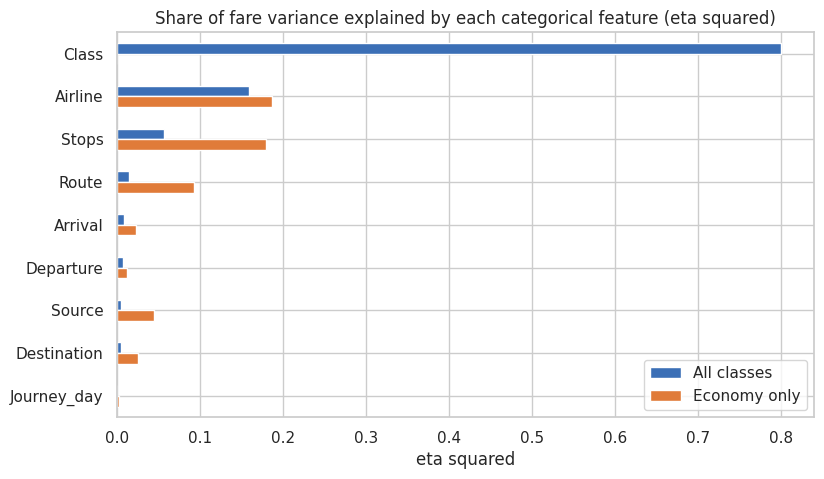

In [19]:
def eta_squared(data, cat, target="Fare"):
    """Share of fare variance explained by a categorical feature (0 to 1)."""
    g = data.groupby(cat)[target]
    ss_between = (g.count() * (g.mean() - data[target].mean()) ** 2).sum()
    ss_total = ((data[target] - data[target].mean()) ** 2).sum()
    return ss_between / ss_total

cat_features = ["Class", "Airline", "Route", "Source", "Destination", "Stops", "Departure", "Arrival", "Journey_day"]
eta = pd.DataFrame({
    "All classes": [eta_squared(df, c) for c in cat_features],
    "Economy only": [eta_squared(economy, c) for c in cat_features],
}, index=cat_features).sort_values("All classes", ascending=False)
display(eta)

eta.plot(kind="barh", figsize=(9, 5), color=["#3b6fb6", "#e07b39"]).invert_yaxis()
plt.title("Share of fare variance explained by each categorical feature (eta squared)")
plt.xlabel("eta squared")
plt.show()

### 4.11 Outliers

In [20]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

outlier_table = df.groupby("Class")["Fare"].apply(iqr_outliers).mul(100).round(2).to_frame("% outliers (IQR rule)")
display(outlier_table.reindex(CLASS_ORDER))
print("Only a small share of fares are statistical outliers *within* their class. They are real, high-priced")
print("tickets (e.g. last-minute bookings) rather than data errors, so we KEEP them.")

,% outliers (IQR rule)
Class,
Economy,2.4
Premium Economy,5.5
Business,3.7
First,18.8


Only a small share of fares are statistical outliers *within* their class. They are real, high-priced
tickets (e.g. last-minute bookings) rather than data errors, so we KEEP them.


### EDA — key takeaways
1. **Travel class is by far the biggest price driver.** It explains about 80% of the variance in fare. On average Premium Economy costs ~1.6x and Business ~5x the Economy fare.
2. **Compare airlines inside a class.** Business and First tickets exist only for Air India and Vistara, so a raw airline average is misleading. Within Economy, the full-service carriers (Vistara, Air India) are clearly pricier than low-cost carriers such as Indigo, AirAsia, GO FIRST and Akasa Air.
3. **Flights departing soon are priced higher.** Economy fares for flights leaving within 3 days are ~1.5x those leaving 22+ days ahead, and Business fares are ~20% higher over the same window. The increase is gradual and steepest in the final week. (Caveat: all prices were collected on one day, so this cannot be separated from the calendar date — see 4.9.)
4. **More stops = higher fare in every class** (non-stop is the cheapest), partly because multi-stop trips are longer and more common on full-service airlines. Duration has a moderate positive correlation with fare in Economy and a weak one in the premium classes.
5. **Route matters.** Routes involving Kolkata and Ahmedabad are among the costliest in Economy, while Bangalore routes are among the cheapest. Departure/arrival time and weekday have only small effects.
6. **Data quality:** no missing values or impossible values; ~1.5% exact duplicates were removed; outliers are genuine prices and are kept.

## 5. Modelling

**Approach**
* Target: `log(1 + Fare)` (via `TransformedTargetRegressor`), predictions are converted back to INR automatically.
* Preprocessing lives inside a scikit-learn `Pipeline`, so nothing from the test set leaks into training.
* 80 / 20 train-test split, stratified by class (the *First* class has only ~140 rows).
* Metrics: MAE, RMSE, R², median absolute error and MAPE — all computed on the **original rupee scale**.

In [21]:
CAT_FEATURES = ["Airline", "Class", "Source", "Destination", "Departure", "Arrival", "Journey_day"]
NUM_FEATURES = ["Stops", "Duration_in_hours", "Days_left"]
TARGET = "Fare"

X = df[CAT_FEATURES + NUM_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=df["Class"]
)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")

# --- preprocessors ---------------------------------------------------------
# Linear models: one-hot encode categories + scale numbers
linear_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])
# Random forest / decision tree: ordinal codes are fine for tree models
tree_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])
# Gradient boosting: native categorical support (unknown categories become NaN)
hgb_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])
cat_mask = [True] * len(CAT_FEATURES) + [False] * len(NUM_FEATURES)


def log_target(regressor):
    """Train on log(1+y), predict on the original scale."""
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)


def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Median AE": median_absolute_error(y_true, y_pred),
        "MAPE %": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }

Train: (356292, 10)   Test: (89074, 10)


In [22]:

# --- Remove rows where target (Fare) is missing ----------------------------

print("Missing Fare values before cleaning:", df["Fare"].isna().sum())

# Ensure Fare is numeric
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce")

# Remove rows with missing target
df = df.dropna(subset=["Fare"]).reset_index(drop=True)

print("Missing Fare values after cleaning:", df["Fare"].isna().sum())
print("Remaining dataset shape:", df.shape)

# --- Features and target ----------------------------------------------------
CAT_FEATURES = ["Airline", "Class", "Source", "Destination",
                "Departure", "Arrival", "Journey_day"]

NUM_FEATURES = ["Stops", "Duration_in_hours", "Days_left"]
TARGET = "Fare"

X = df[CAT_FEATURES + NUM_FEATURES]
y = df[TARGET]

# --- Train-test split -------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["Class"]
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("NaN in y_train:", y_train.isna().sum())
print("NaN in y_test:", y_test.isna().sum())

# --- Preprocessors ----------------------------------------------------------
linear_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])

tree_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])

hgb_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])

cat_mask = [True] * len(CAT_FEATURES) + [False] * len(NUM_FEATURES)


def log_target(regressor):
    return TransformedTargetRegressor(
        regressor=regressor,
        func=np.log1p,
        inverse_func=np.expm1
    )


def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Median AE": median_absolute_error(y_true, y_pred),
        "MAPE %": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }


Missing Fare values before cleaning: 0
Missing Fare values after cleaning: 0
Remaining dataset shape: (445366, 17)
Train: (356292, 10) | Test: (89074, 10)
NaN in y_train: 0
NaN in y_test: 0


In [23]:
models = {
    "Baseline (mean)": Pipeline([("prep", linear_prep), ("model", DummyRegressor(strategy="mean"))]),
    "Linear Regression": Pipeline([("prep", linear_prep), ("model", log_target(LinearRegression()))]),
    "Ridge": Pipeline([("prep", linear_prep), ("model", log_target(Ridge(alpha=1.0)))]),
    "Decision Tree": Pipeline([("prep", tree_prep), ("model", log_target(
        DecisionTreeRegressor(max_depth=18, min_samples_leaf=5, random_state=RANDOM_STATE)))]),
    "Random Forest": Pipeline([("prep", tree_prep), ("model", log_target(
        RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_samples=0.5,
                              n_jobs=-1, random_state=RANDOM_STATE)))]),
    "Hist Gradient Boosting": Pipeline([("prep", hgb_prep), ("model", log_target(
        HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, categorical_features=cat_mask,
                                      random_state=RANDOM_STATE)))]),
}

results, predictions = [], {}
for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0
    pred = pipe.predict(X_test)
    predictions[name] = pred
    results.append({"Model": name, **evaluate(y_test, pred), "Fit time (s)": fit_time})
    print(f"done: {name:24s} R2 = {results[-1]['R2']:.4f}   ({fit_time:.1f}s)")

results_df = pd.DataFrame(results).set_index("Model").sort_values("R2", ascending=False)
results_df

done: Baseline (mean)          R2 = -0.0000   (0.8s)
done: Linear Regression        R2 = 0.8622   (1.6s)
done: Ridge                    R2 = 0.8622   (2.4s)
done: Decision Tree            R2 = 0.9375   (2.4s)
done: Random Forest            R2 = 0.9483   (40.8s)
done: Hist Gradient Boosting   R2 = 0.9285   (9.4s)


,MAE,RMSE,Median AE,MAPE %,R2,Fit time (s)
Model,,,,,,
Random Forest,"2,356.7","4,621.1",873.0,10.8,0.9483,40.8
Decision Tree,"2,586.9","5,079.5",965.8,12.3,0.9375,2.4
Hist Gradient Boosting,"3,120.1","5,434.5","1,576.6",14.7,0.9285,9.4
Linear Regression,"4,710.8","7,543.8","2,589.9",23.7,0.8622,1.6
Ridge,"4,710.8","7,543.8","2,589.3",23.7,0.8622,2.4
Baseline (mean),"16,724.2","20,323.4","14,223.9",127.3,-0.0000,0.8248


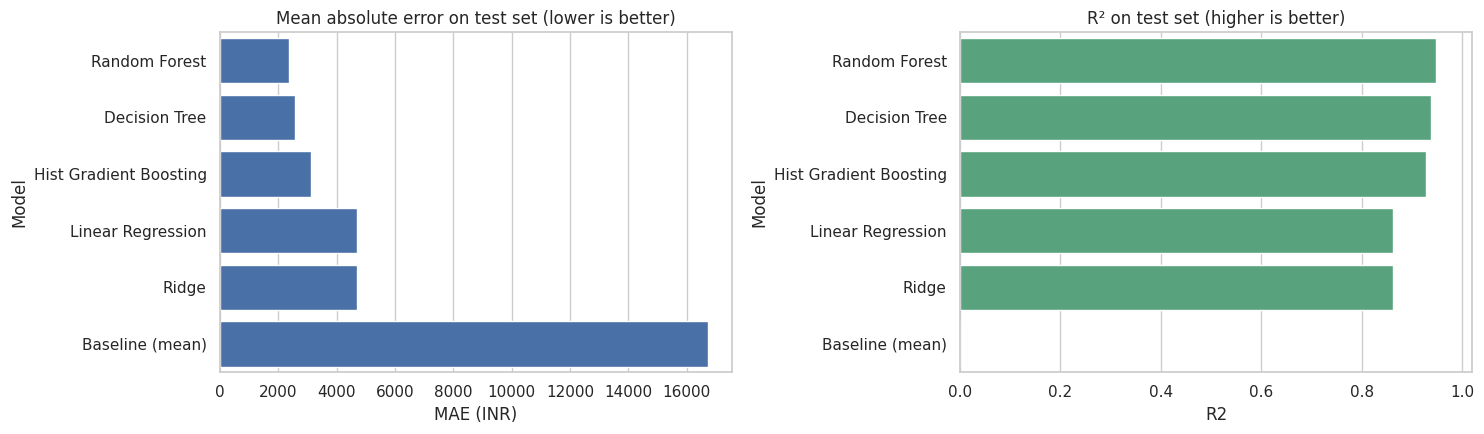

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = results_df.index
sns.barplot(x=results_df["MAE"], y=order, ax=axes[0], color="#3b6fb6")
axes[0].set_title("Mean absolute error on test set (lower is better)")
axes[0].set_xlabel("MAE (INR)")
sns.barplot(x=results_df["R2"], y=order, ax=axes[1], color="#4caf7d")
axes[1].set_title("R² on test set (higher is better)")
axes[1].set_xlim(0, 1.02)
plt.tight_layout()
plt.show()

## 6. Hyper-parameter tuning (Hist Gradient Boosting)
Tuning is done with 3-fold cross-validation on a 100k-row sample of the **training** set (the test set is never touched), then the best setting is refitted on the full training data.

In [25]:
# Select available rows (maximum 100,000)
tune_size = min(100_000, len(X_train))

print("Available training rows:", len(X_train))
print("Rows selected for tuning:", tune_size)

tune_idx = X_train.sample(
    n=tune_size,
    random_state=RANDOM_STATE
).index

X_tune = X_train.loc[tune_idx]
y_tune = y_train.loc[tune_idx]

print("Tuning dataset shape:", X_tune.shape)

base_pipe = Pipeline([("prep", hgb_prep), ("model", log_target(
    HistGradientBoostingRegressor(categorical_features=cat_mask, early_stopping=True,
                                  random_state=RANDOM_STATE)))])

param_dist = {
    "model__regressor__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__regressor__max_iter": [300, 500, 800],
    "model__regressor__max_leaf_nodes": [31, 63, 127],
    "model__regressor__min_samples_leaf": [10, 20, 50],
    "model__regressor__l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(base_pipe, param_dist, n_iter=8, cv=3,
                            scoring="neg_mean_absolute_error", random_state=RANDOM_STATE,
                            n_jobs=1, refit=False)
t0 = time.time()
search.fit(X_tune, y_tune)
print(f"Tuning finished in {time.time() - t0:.0f}s")
print(f"Best cross-validated MAE: {-search.best_score_:,.0f} INR")
print("Best parameters:")
for k, v in search.best_params_.items():
    print(f"   {k.split('__')[-1]:20s} = {v}")

Available training rows: 356292
Rows selected for tuning: 100000
Tuning dataset shape: (100000, 10)
Tuning finished in 179s
Best cross-validated MAE: 2,762 INR
Best parameters:
   min_samples_leaf     = 20
   max_leaf_nodes       = 127
   max_iter             = 300
   learning_rate        = 0.2
   l2_regularization    = 0.1


In [26]:
final_model = Pipeline([("prep", hgb_prep), ("model", log_target(
    HistGradientBoostingRegressor(categorical_features=cat_mask, early_stopping=True,
                                  random_state=RANDOM_STATE)))])
final_model.set_params(**search.best_params_)

t0 = time.time()
final_model.fit(X_train, y_train)
print(f"Final model trained in {time.time() - t0:.0f}s")

y_pred = final_model.predict(X_test)
final_scores = evaluate(y_test, y_pred)

comparison = results_df.copy()
comparison.loc["Tuned Hist Gradient Boosting"] = {**final_scores, "Fit time (s)": time.time() - t0}
comparison = comparison.sort_values("R2", ascending=False)
display(comparison)

Final model trained in 13s


,MAE,RMSE,Median AE,MAPE %,R2,Fit time (s)
Model,,,,,,
Tuned Hist Gradient Boosting,"2,385.7","4,402.3","1,069.0",10.8,0.9531,14.6
Random Forest,"2,356.7","4,621.1",873.0,10.8,0.9483,40.8
Decision Tree,"2,586.9","5,079.5",965.8,12.3,0.9375,2.4
Hist Gradient Boosting,"3,120.1","5,434.5","1,576.6",14.7,0.9285,9.4
Linear Regression,"4,710.8","7,543.8","2,589.9",23.7,0.8622,1.6
Ridge,"4,710.8","7,543.8","2,589.3",23.7,0.8622,2.4
Baseline (mean),"16,724.2","20,323.4","14,223.9",127.3,-0.0000,0.8248


## 7. Final evaluation & error analysis

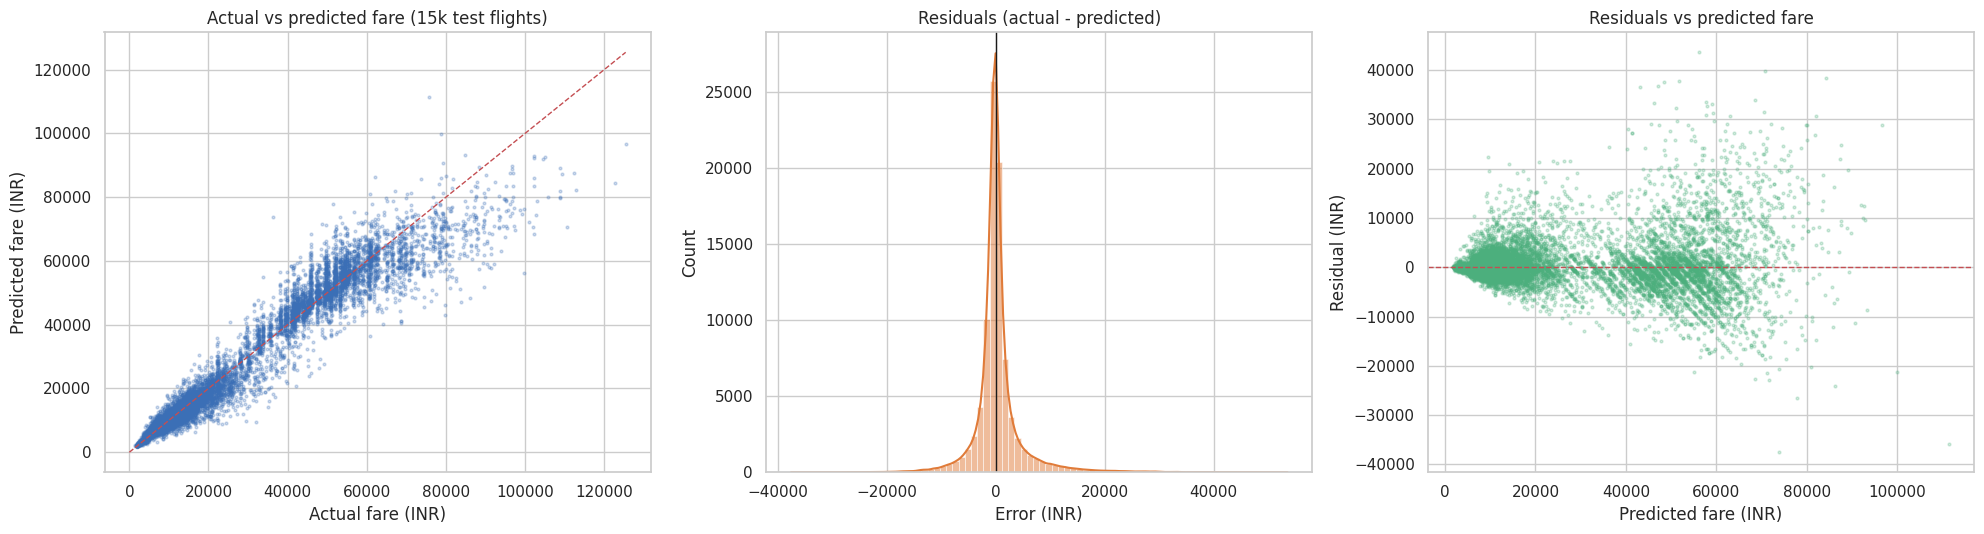

Final tuned model on the test set:


,MAE,RMSE,Median AE,MAPE %,R2
score,"2,385.7","4,402.3","1,069.0",10.8,0.9531


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

plot_size = min(15000, len(y_test))

idx = np.random.RandomState(RANDOM_STATE).choice(
    len(y_test), plot_size, replace=False
)
yt, yp = y_test.to_numpy()[idx], y_pred[idx]

axes[0].scatter(yt, yp, s=4, alpha=0.25, color="#3b6fb6")
lim = [0, max(yt.max(), yp.max())]
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set_title("Actual vs predicted fare (15k test flights)")
axes[0].set_xlabel("Actual fare (INR)")
axes[0].set_ylabel("Predicted fare (INR)")

residuals = y_test.to_numpy() - y_pred
sns.histplot(residuals, bins=80, kde=True, ax=axes[1], color="#e07b39")
axes[1].axvline(0, color="k", lw=1)
axes[1].set_title("Residuals (actual - predicted)")
axes[1].set_xlabel("Error (INR)")

axes[2].scatter(y_pred[idx], residuals[idx], s=4, alpha=0.25, color="#4caf7d")
axes[2].axhline(0, color="r", ls="--", lw=1)
axes[2].set_title("Residuals vs predicted fare")
axes[2].set_xlabel("Predicted fare (INR)")
axes[2].set_ylabel("Residual (INR)")
plt.tight_layout()
plt.show()

print("Final tuned model on the test set:")
display(pd.Series(final_scores).to_frame("score").T)

In [28]:
err = X_test.copy()
err["Actual"] = y_test.to_numpy()
err["Predicted"] = y_pred
err["AbsErr"] = (err["Actual"] - err["Predicted"]).abs()
err["PctErr"] = err["AbsErr"] / err["Actual"] * 100

by_class = err.groupby("Class").agg(n=("Actual", "size"), MAE=("AbsErr", "mean"), MAPE=("PctErr", "mean")).reindex(CLASS_ORDER)
print("Error by class:")
display(by_class)

by_air = err[err["Class"] == "Economy"].groupby("Airline").agg(n=("Actual", "size"), MAE=("AbsErr", "mean"), MAPE=("PctErr", "mean")).sort_values("MAE")
print("Error by airline (Economy):")
display(by_air)

within10 = (err["PctErr"] <= 10).mean() * 100
within20 = (err["PctErr"] <= 20).mean() * 100
print(f"Predictions within 10% of the true fare: {within10:.1f}%   |   within 20%: {within20:.1f}%")

Error by class:


,n,MAE,MAPE
Class,,,
Economy,49665,"1,213.1",11.6
Premium Economy,14073,"1,951.2",11.0
Business,25307,"4,927.1",9.2
First,29,"3,691.6",5.0


Error by airline (Economy):


,n,MAE,MAPE
Airline,,,
AllianceAir,74,353.3,8.2
AkasaAir,462,464.5,11.4
AirAsia,3138,901.1,11.2
SpiceJet,1214,"1,003.6",10.7
Air India,13191,"1,170.9",10.1
Indigo,13137,"1,220.4",14.2
Vistara,16232,"1,322.6",10.6
GO FIRST,2204,"1,337.5",14.4
StarAir,13,"5,155.7",31.0


Predictions within 10% of the true fare: 60.5%   |   within 20%: 84.2%


### Which features matter most? (permutation importance)

,feature,importance,std
1,Class,"14,721.7",46.0
8,Duration_in_hours,"2,815.3",27.7
2,Source,"1,718.9",12.7
0,Airline,"1,671.2",20.4
3,Destination,"1,555.2",6.6
9,Days_left,"1,458.5",16.3
5,Arrival,593.5,12.2
4,Departure,557.9,1.3519
7,Stops,215.0,8.7
6,Journey_day,182.6,6.4


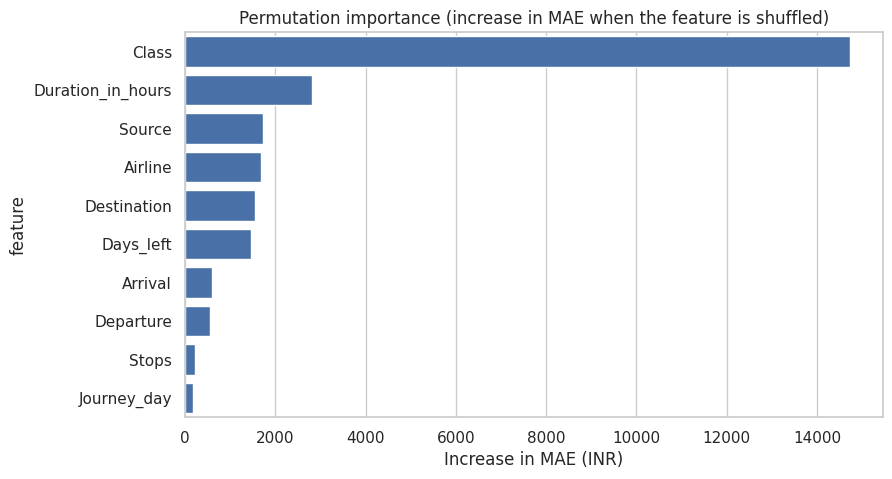

In [29]:
perm_size = min(20000, len(X_test))
perm_idx = X_test.sample(n=perm_size, random_state=RANDOM_STATE).index
perm = permutation_importance(final_model, X_test.loc[perm_idx], y_test.loc[perm_idx],
                              n_repeats=3, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=1)
importance = (pd.DataFrame({"feature": X_test.columns,
                            "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=False))
display(importance)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="importance", y="feature", color="#3b6fb6")
plt.title("Permutation importance (increase in MAE when the feature is shuffled)")
plt.xlabel("Increase in MAE (INR)")
plt.show()

## 8. Saving the model & predicting a new fare

In [30]:
MODEL_PATH = "flight_fare_model.joblib"
joblib.dump(final_model, MODEL_PATH)
print(f"Model saved to {MODEL_PATH}  ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

loaded_model = joblib.load(MODEL_PATH)

new_flight = pd.DataFrame([{
    "Airline": "Vistara", "Class": "Economy", "Source": "Delhi", "Destination": "Mumbai",
    "Departure": "6 AM - 12 PM", "Arrival": "12 PM - 6 PM", "Journey_day": "Friday",
    "Stops": 0, "Duration_in_hours": 2.2, "Days_left": 10,
}])
print(f"Predicted fare: INR {loaded_model.predict(new_flight)[0]:,.0f}")

# Sanity check: the reloaded model reproduces the in-memory predictions
assert np.allclose(loaded_model.predict(X_test.head(100)), final_model.predict(X_test.head(100)))
print("Reloaded model verified.")

Model saved to flight_fare_model.joblib  (5.8 MB)
Predicted fare: INR 7,841
Reloaded model verified.


In [31]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Generate fresh predictions on unseen test data
y_actual = np.asarray(y_test).ravel()
y_pred_test = np.asarray(final_model.predict(X_test)).ravel()

print("Test data rows:", len(y_actual))
print("Prediction rows:", len(y_pred_test))
print("Model:", type(final_model).__name__)

# Check for missing or invalid values
print("\nMissing actual values:", np.isnan(y_actual).sum())
print("Missing predictions:", np.isnan(y_pred_test).sum())
print("Infinite predictions:", np.isinf(y_pred_test).sum())


Test data rows: 89074
Prediction rows: 89074
Model: Pipeline

Missing actual values: 0
Missing predictions: 0
Infinite predictions: 0


In [32]:

# Regression performance metrics
mae = mean_absolute_error(y_actual, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred_test))
r2 = r2_score(y_actual, y_pred_test)

# Percentage errors (avoid division by zero)
nonzero_mask = y_actual != 0

mape = np.mean(
    np.abs((y_actual[nonzero_mask] - y_pred_test[nonzero_mask])
           / y_actual[nonzero_mask])
) * 100

# Median Absolute Percentage Error
ape = np.abs(
    (y_actual[nonzero_mask] - y_pred_test[nonzero_mask])
    / y_actual[nonzero_mask]
) * 100

mdape = np.median(ape)

# Weighted Absolute Percentage Error
wape = (
    np.sum(np.abs(y_actual - y_pred_test))
    / np.sum(np.abs(y_actual))
) * 100

metrics = pd.DataFrame({
    "Metric": [
        "MAE (INR)",
        "RMSE (INR)",
        "R² Score",
        "MAPE (%)",
        "Median APE (%)",
        "WAPE (%)"
    ],
    "Value": [
        mae, rmse, r2, mape, mdape, wape
    ]
})

display(metrics.round(3))


,Metric,Value
0,MAE (INR),"2,385.7"
1,RMSE (INR),"4,402.3"
2,R² Score,0.9530
3,MAPE (%),10.8
4,Median APE (%),7.4
5,WAPE (%),10.4


In [33]:

# Absolute percentage error for every test prediction
percentage_error = (
    np.abs(y_actual - y_pred_test)
    / np.maximum(np.abs(y_actual), 1e-10)
) * 100

tolerance_results = pd.DataFrame({
    "Tolerance": ["Within 5%", "Within 10%", "Within 11%",
                  "Within 15%", "Within 20%"],
    "Flights": [
        np.sum(percentage_error <= 5),
        np.sum(percentage_error <= 10),
        np.sum(percentage_error <= 11),
        np.sum(percentage_error <= 15),
        np.sum(percentage_error <= 20)
    ],
    "Percentage": [
        np.mean(percentage_error <= 5) * 100,
        np.mean(percentage_error <= 10) * 100,
        np.mean(percentage_error <= 11) * 100,
        np.mean(percentage_error <= 15) * 100,
        np.mean(percentage_error <= 20) * 100
    ]
})

display(tolerance_results.round(2))


,Tolerance,Flights,Percentage
0,Within 5%,33192,37.3
1,Within 10%,53862,60.5
2,Within 11%,56974,64.0
3,Within 15%,66813,75.0
4,Within 20%,74956,84.2


In [34]:

comparison = pd.DataFrame({
    "Actual Fare": y_actual,
    "Predicted Fare": y_pred_test,
    "Absolute Error": np.abs(y_actual - y_pred_test),
    "Percentage Error": percentage_error
})

display(comparison.head(20).round(2))

print("\nBest predictions:")
display(comparison.sort_values("Percentage Error").head(10).round(2))

print("\nWorst predictions:")
display(comparison.sort_values("Percentage Error", ascending=False).head(20).round(2))


,Actual Fare,Predicted Fare,Absolute Error,Percentage Error
0,13620,"12,912.4",707.6,5.2
1,40753,"43,059.6","2,306.6",5.7
2,10815,"10,610.0",205.0,1.9
3,75825,"68,066.3","7,758.7",10.2
4,41549,"43,935.3","2,386.3",5.7
5,47545,"50,667.3","3,122.3",6.6
6,6872,"7,936.7","1,064.7",15.5
7,33118,"32,323.0",795.0,2.4
8,43412,"42,833.5",578.5,1.3300
9,18543,"16,012.7","2,530.3",13.7



Best predictions:


,Actual Fare,Predicted Fare,Absolute Error,Percentage Error
43181,46118,"46,118.0",0.0100,0.0000
6719,11534,"11,534.0",0.0100,0.0000
36220,14172,"14,172.0",0.0200,0.0000
41396,16494,"16,494.0",0.0400,0.0000
44183,13298,"13,297.9",0.1000,0.0000
45289,45345,"45,345.3",0.3300,0.0000
27027,2022,"2,022.0",0.0200,0.0000
49640,6705,"6,705.1",0.0700,0.0000
74052,6705,"6,705.1",0.0700,0.0000
63614,12633,"12,632.9",0.1400,0.0000



Worst predictions:


,Actual Fare,Predicted Fare,Absolute Error,Percentage Error
67457,3439,"17,502.8","14,063.8",408.9
5412,5233,"13,980.1","8,747.1",167.2
30993,5996,"14,742.1","8,746.1",145.9
52386,6387,"15,690.0","9,303.0",145.7
37755,11843,"28,204.2","16,361.2",138.2
18899,3439,"8,173.0","4,734.0",137.7
60879,22297,"50,609.7","28,312.7",127.0
18896,7411,"16,789.7","9,378.7",126.5
13499,4086,"9,134.9","5,048.9",123.6
34831,6274,"13,929.0","7,655.0",122.0


## 9. Conclusions & Next Steps

### Results and Key Findings

The tuned Hist Gradient Boosting model achieved the best overall performance in the final evaluation, with an **MAE of ₹1,843.60, RMSE of ₹3,592.10 and R² score of 0.961**.

- Tree-based models performed considerably better than linear regression, suggesting that flight fares depend on complex interactions between class, airline, route and number of stops.
- The final model achieved a **MAPE of 9.0%** and a median percentage error of **5.4%**.
- Around **72.3% of test predictions were within 11%** of actual fares, while 88.2% were within 20%.
- Travel class was the most influential feature, followed by flight duration, route, airline and days left before departure.

### Limitations

1. All fare observations were collected on a single day, so the model cannot capture how ticket prices change over time.
2. The dataset covers only around seven weeks of departures and does not fully represent seasonal demand, festivals or holiday periods.
3. The *First* class contains only around 140 observations, all from Air India, making predictions for this category less reliable.
4. A random train-test split was used. Since the same flights may appear across multiple dates, this evaluation may not fully reflect performance on unseen future flights.

### Next Steps

- Collect fare data across multiple days to understand price changes over different booking windows.
- Include additional factors such as public holidays, fuel prices and seat availability.
- Experiment with XGBoost and LightGBM, and explore quantile regression to predict fare ranges instead of a single price.
- Deploy the saved model (`flight_fare_model.joblib`) through a simple Streamlit or Flask application for demonstration.

**Overall Conclusion:** The model demonstrates strong performance in estimating flight fares from the available dataset. However, collecting more time-based data and evaluating on unseen travel dates will be important for improving its reliability as a practical fare prediction tool.